In [2]:
import io
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

# The project folder contains code/, inputs/ and outputs/
ROOT = Path.cwd().parent if Path.cwd().name == "code" else Path.cwd()
INPUTS = ROOT / "inputs"
FIG = ROOT / "outputs" / "figures"
TAB = ROOT / "outputs" / "tables"
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)

# Large fonts and 300 dpi so the figures stay sharp on slides
plt.rcParams.update({"font.size": 14, "axes.labelsize": 15, "axes.grid": True,
                     "grid.alpha": 0.4, "savefig.dpi": 300, "savefig.bbox": "tight",
                     "savefig.facecolor": "white"})
print("Files found in inputs/:", [f.name for f in INPUTS.glob("*.zip")])

Files found in inputs/: ['AAV2020_au_01-01-2024.zip', 'base-cc-emploi-pop-active-2021_csv.zip', 'fonds_aav2020_2024.zip']


In [9]:
   %pip install openpyxl geopandas


   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   ---------------------------------------- 2/2 [openpyxl]

Note: you may need to restart the kernel to use update

In [3]:
import urllib.request

FILES = {
    "base-cc-emploi-pop-active-2021_csv.zip":
        "https://www.insee.fr/fr/statistiques/fichier/8202916/base-cc-emploi-pop-active-2021_csv.zip",
    "AAV2020_au_01-01-2024.zip":
        "https://www.insee.fr/fr/statistiques/fichier/4803954/AAV2020_au_01-01-2024.zip",
    "fonds_aav2020_2024.zip":
        "https://www.insee.fr/fr/statistiques/fichier/4803954/fonds_aav2020_2024.zip",
}

INPUTS.mkdir(parents=True, exist_ok=True)
for name, url in FILES.items():
    target = INPUTS / name
    if target.exists():
        print("Already there:", name)
        continue
    print("Downloading", name, "...")
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req) as r, open(target, "wb") as f:
        f.write(r.read())
    print("  done,", round(target.stat().st_size / 1e6, 1), "MB")

print("Files in inputs/:", [f.name for f in INPUTS.glob("*.zip")])

Already there: base-cc-emploi-pop-active-2021_csv.zip
Already there: AAV2020_au_01-01-2024.zip
Already there: fonds_aav2020_2024.zip
Files in inputs/: ['AAV2020_au_01-01-2024.zip', 'base-cc-emploi-pop-active-2021_csv.zip', 'fonds_aav2020_2024.zip']


In [4]:
POP = "P21_POP1564"                       # population aged 15 to 64
GROUPS = {
    "managers": "C21_ACT1564_CS3",        # cadres
    "workers": "C21_ACT1564_CS6",         # ouvriers
    "graduates": "P21_ACT_SUP5",          # labour force with a master's degree or more
    "no_diploma": "P21_ACT_DIPLMIN",      # labour force with no diploma
}
keep = ["CODGEO", "LIBGEO", POP] + list(GROUPS.values())

census_zip = next(INPUTS.glob("base-cc-emploi-pop-active-2021*.zip"))
tables = []
with zipfile.ZipFile(census_zip) as z:
    for name in z.namelist():
        if name.lower().endswith(".csv"):
            tables.append(pd.read_csv(z.open(name), sep=";", dtype=str,
                                      usecols=lambda c: c in keep))
census = pd.concat(tables, ignore_index=True).drop_duplicates("CODGEO")

# Counts are weighted estimates (they can have decimals): convert text to numbers
for col in [POP] + list(GROUPS.values()):
    census[col] = pd.to_numeric(census[col].str.replace(",", "."), errors="coerce").fillna(0)

# Check that every column exists, and show the totals for France
missing = [c for c in [POP] + list(GROUPS.values()) if c not in census.columns]
print(len(census), "municipalities. Missing columns:", missing if missing else "none")
totals = census[[POP] + list(GROUPS.values())].sum().round(0).astype(int)
totals.index = ["population 15-64"] + list(GROUPS.keys())
print(totals.to_string())

34963 municipalities. Missing columns: none
population 15-64    44131145
managers             6198846
workers              6596931
graduates            5620197
no_diploma           3212057


In [5]:
PLM_PARENT = {"751": "75056", "6938": "69123", "132": "13055"}

def parent_commune(code):
    for prefix, parent in PLM_PARENT.items():
        if code.startswith(prefix) and code != parent:
            return parent
    return code

census["COM_PARENT"] = census["CODGEO"].map(parent_commune)
if (census["COM_PARENT"] != census["CODGEO"]).any():
    # drop the whole-city rows so that nobody is counted twice
    census = census[~census["CODGEO"].isin(PLM_PARENT.values())]
    print("Arrondissements used for Paris, Lyon and Marseille.")
else:
    print("WARNING: no arrondissements found.")

Arrondissements used for Paris, Lyon and Marseille.


In [7]:
def strip_styles(xlsx_bytes):
    # Rebuild the Excel file without its style sheet (the Insee one has a broken colour)
    src = zipfile.ZipFile(io.BytesIO(xlsx_bytes))
    clean = io.BytesIO()
    with zipfile.ZipFile(clean, "w", zipfile.ZIP_DEFLATED) as dst:
        for item in src.namelist():
            if item != "xl/styles.xml":
                dst.writestr(item, src.read(item))
    clean.seek(0)
    return clean

def read_insee_excel(source, sheet, first_col="CODGEO"):
    # Insee Excel files start with title lines: find the row with the column names
    raw = pd.read_excel(source, sheet_name=sheet, header=None, dtype=str)
    header_row = raw.index[raw.iloc[:, 0].astype(str).str.strip() == first_col][0]
    df = raw.iloc[header_row + 1:].copy()
    df.columns = raw.iloc[header_row].astype(str).str.strip()
    return df.reset_index(drop=True)

aav_zip = next(INPUTS.glob("AAV2020_au_*.zip"))
with zipfile.ZipFile(aav_zip) as z:
    xlsx = [n for n in z.namelist() if n.lower().endswith(".xlsx")][0]
    xl = pd.ExcelFile(strip_styles(z.read(xlsx)))
sheet = [s for s in xl.sheet_names if "compo" in s.lower()][0]
aav = read_insee_excel(xl, sheet)[["CODGEO", "AAV2020", "LIBAAV2020"]]

units = census.merge(aav, left_on="COM_PARENT", right_on="CODGEO", suffixes=("", "_aav"))
units = units[units["AAV2020"] != "000"]          # '000' = outside any city
print(f"{len(units):,} municipalities in {units['AAV2020'].nunique()} cities")

26,039 municipalities in 698 cities


In [8]:
def duncan(a, b):
    A, B = a.sum(), b.sum()
    if A == 0 or B == 0:
        return np.nan
    return 0.5 * np.abs(a / A - b / B).sum()

print(duncan(pd.Series([50, 30, 20]), pd.Series([10, 30, 60])))

0.4


In [9]:
def city_stats(g):
    return pd.Series({
        "name": g["LIBAAV2020"].iloc[0],
        "pop": g[POP].sum(),
        "n_units": len(g),
        "D_occupation": duncan(g[GROUPS["managers"]], g[GROUPS["workers"]]),
        "D_education": duncan(g[GROUPS["graduates"]], g[GROUPS["no_diploma"]]),
    })

cities = units.groupby("AAV2020").apply(city_stats, include_groups=False).reset_index()
# a city made of one municipality has D = 0 by construction: no information, so we drop it
cities = cities[(cities["n_units"] >= 2) & cities["D_occupation"].notna()].copy()
cities["log_pop"] = np.log(cities["pop"].astype(float))
cities["log_units"] = np.log(cities["n_units"].astype(float))
cities.to_csv(TAB / "cities_segregation.csv", index=False)

print(len(cities), "cities kept")
cities.sort_values("pop", ascending=False).head(10)

638 cities kept


,AAV2020,name,pop,n_units,D_occupation,D_education,log_pop,log_units
0,001,Paris,8.615204e+06,1948,0.447927,0.445343,15.969039,7.574558
1,002,Lyon,1.478193e+06,405,0.361763,0.378947,14.206331,6.003887
2,003,Marseille - Aix-en-Provence,1.172155e+06,130,0.326547,0.360914,13.974354,4.867534
3,004,Lille (partie française),9.868290e+05,201,0.372190,0.368322,13.802252,5.303305
4,005,Toulouse,9.844804e+05,527,0.240248,0.244696,13.799869,6.267201
5,006,Bordeaux,9.027415e+05,275,0.323775,0.338616,13.713192,5.616771
6,008,Nantes,6.682431e+05,116,0.280385,0.215405,13.412407,4.753590
7,010,Strasbourg (partie française),5.614776e+05,268,0.224009,0.185976,13.238327,5.590987
8,012,Montpellier,5.268486e+05,161,0.212759,0.229293,13.174669,5.081404
9,013,Rennes,5.060317e+05,183,0.289069,0.218880,13.134355,5.209486


In [10]:
cities[["pop", "n_units", "D_occupation", "D_education"]].describe().round(3)

,pop,n_units,D_occupation,D_education
count,638.000,638.000,638.000,638.000
mean,60937.171,40.719,0.197,0.170
std,360448.700,94.052,0.082,0.075
min,1528.192,2.000,0.005,0.000
25%,5436.913,8.000,0.151,0.123
50%,11881.060,18.500,0.197,0.168
75%,34143.042,44.000,0.244,0.214
max,8615203.888,1948.000,0.543,0.445


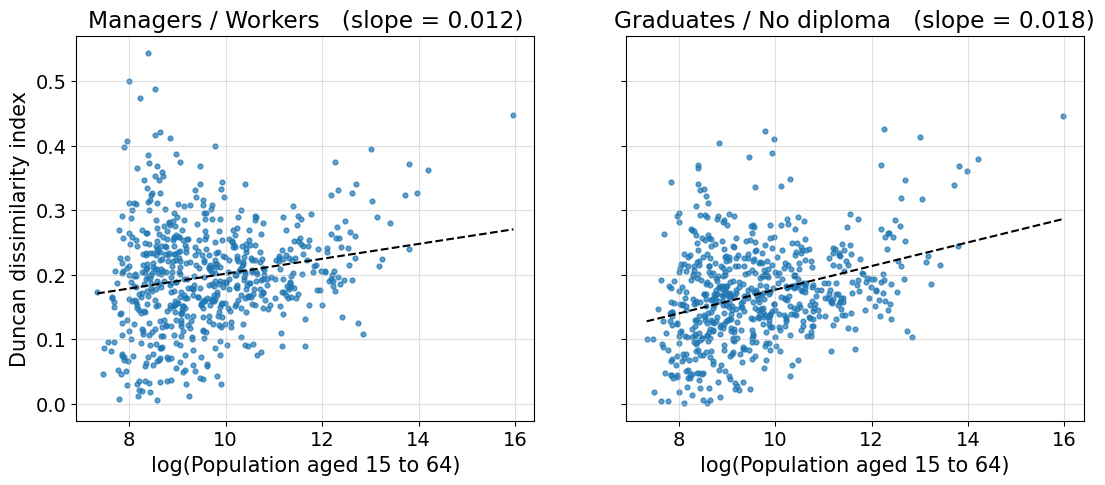

In [11]:
DEFINITIONS = {"D_occupation": "Managers / Workers", "D_education": "Graduates / No diploma"}

def two_panels(df, x, xlabel, filename, color="tab:blue"):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
    for ax, (y, title) in zip(axes, DEFINITIONS.items()):
        ax.scatter(df[x], df[y], s=12, alpha=0.7, color=color)
        fit = smf.ols(f"{y} ~ {x}", data=df).fit()
        xs = np.linspace(df[x].min(), df[x].max(), 100)
        ax.plot(xs, fit.params["Intercept"] + fit.params[x] * xs, "k--", lw=1.5)
        ax.set_title(f"{title}   (slope = {fit.params[x]:.3f})")
        ax.set_xlabel(xlabel)
    axes[0].set_ylabel("Duncan dissimilarity index")
    fig.savefig(FIG / filename)
    plt.show()

two_panels(cities, "log_pop", "log(Population aged 15 to 64)", "fig1_D_vs_logpop.png")

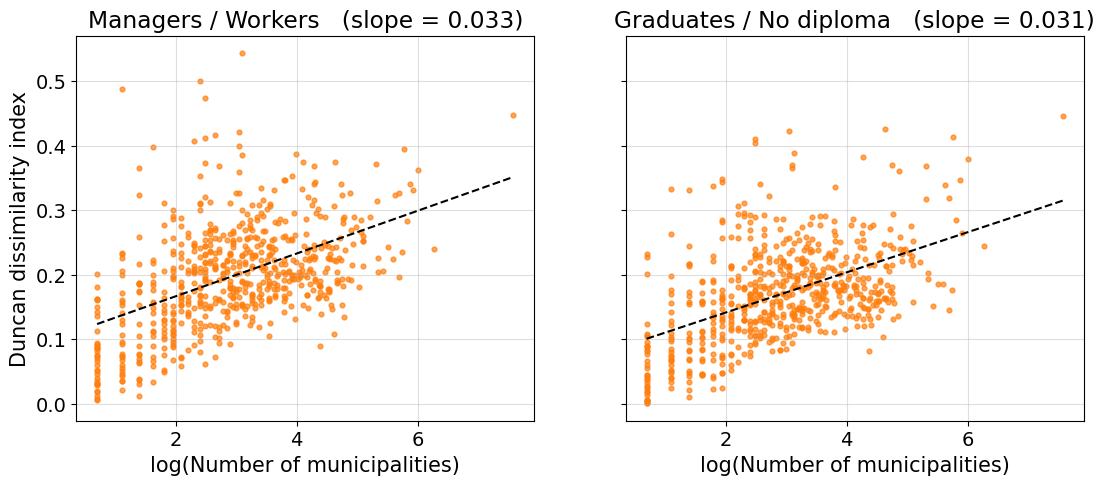

Correlation between log(population) and log(number of municipalities): 0.76


In [12]:
two_panels(cities, "log_units", "log(Number of municipalities)", "fig2_D_vs_logunits.png",
           color="tab:orange")
print("Correlation between log(population) and log(number of municipalities):",
      round(cities["log_pop"].corr(cities["log_units"]), 2))

454 cities with at least 10 municipalities


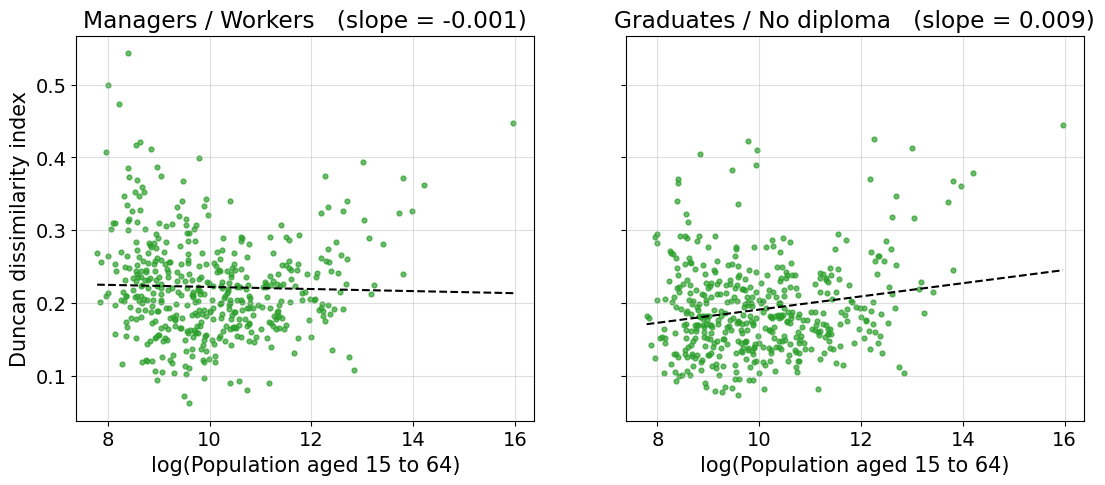

In [13]:
MIN_UNITS = 10
restricted = cities[cities["n_units"] >= MIN_UNITS]
print(len(restricted), "cities with at least", MIN_UNITS, "municipalities")
two_panels(restricted, "log_pop", "log(Population aged 15 to 64)",
           "fig3_D_vs_logpop_restricted.png", color="tab:green")

In [14]:
results = {}
for y, title in DEFINITIONS.items():
    results[f"{title} (1)"] = smf.ols(f"{y} ~ log_pop", data=cities).fit(cov_type="HC1")
    results[f"{title} (2)"] = smf.ols(f"{y} ~ log_pop + log_units", data=cities).fit(cov_type="HC1")
    results[f"{title} (3)"] = smf.ols(f"{y} ~ log_pop + log_units", data=restricted).fit(cov_type="HC1")

for k, r in results.items():
    b = r.params["log_pop"]
    print(f"{k:28s} beta1 = {b:.4f} (se {r.bse['log_pop']:.4f}, p = {r.pvalues['log_pop']:.3f})"
          f"  doubling population -> D + {0.69 * b:.3f}  R2 = {r.rsquared:.3f}")

Managers / Workers (1)       beta1 = 0.0115 (se 0.0025, p = 0.000)  doubling population -> D + 0.008  R2 = 0.036
Managers / Workers (2)       beta1 = -0.0258 (se 0.0037, p = 0.000)  doubling population -> D + -0.018  R2 = 0.319
Managers / Workers (3)       beta1 = -0.0281 (se 0.0044, p = 0.000)  doubling population -> D + -0.019  R2 = 0.151
Graduates / No diploma (1)   beta1 = 0.0184 (se 0.0023, p = 0.000)  doubling population -> D + 0.013  R2 = 0.109
Graduates / No diploma (2)   beta1 = -0.0065 (se 0.0032, p = 0.043)  doubling population -> D + -0.004  R2 = 0.257
Graduates / No diploma (3)   beta1 = -0.0044 (se 0.0040, p = 0.275)  doubling population -> D + -0.003  R2 = 0.081


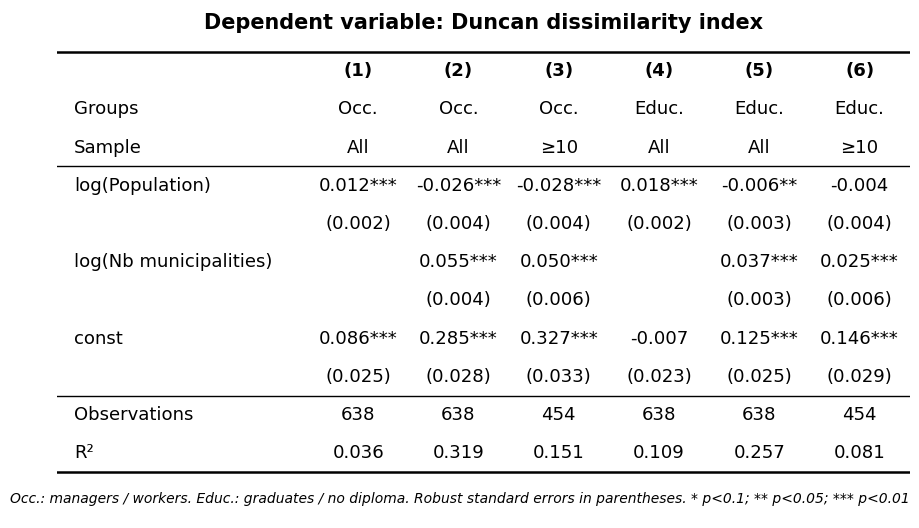

In [15]:
def stars(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.1 else ""

labels = {"log_pop": "log(Population)", "log_units": "log(Nb municipalities)", "Intercept": "const"}
header = ["", "(1)", "(2)", "(3)", "(4)", "(5)", "(6)"]
rows = [["Groups", "Occ.", "Occ.", "Occ.", "Educ.", "Educ.", "Educ."],
        ["Sample", "All", "All", f"≥{MIN_UNITS}", "All", "All", f"≥{MIN_UNITS}"]]
for var in labels:
    coefs, ses = [labels[var]], [""]
    for r in results.values():
        coefs.append(f"{r.params[var]:.3f}{stars(r.pvalues[var])}" if var in r.params else "")
        ses.append(f"({r.bse[var]:.3f})" if var in r.params else "")
    rows += [coefs, ses]
rows.append(["Observations"] + [str(int(r.nobs)) for r in results.values()])
rows.append(["R²"] + [f"{r.rsquared:.3f}" for r in results.values()])
pd.DataFrame(rows, columns=header).to_csv(TAB / "regressions_table.csv", index=False,
                                          encoding="utf-8-sig")

table_rows = [header] + rows
n, h = len(table_rows), 0.5
col_x = [0.0, 3.4, 4.6, 5.8, 7.0, 8.2, 9.4]
fig, ax = plt.subplots(figsize=(11, h * (n + 2.2)))
ax.set_xlim(-0.2, 10.0)
ax.set_ylim(-(n + 1.2) * h, 1.1 * h)
ax.axis("off")
ax.text(4.9, 0.6 * h, "Dependent variable: Duncan dissimilarity index", ha="center",
        fontsize=15, weight="bold")
for i, row in enumerate(table_rows):
    for j, value in enumerate(row):
        ax.text(col_x[j], -(i + 0.5) * h, value, ha="left" if j == 0 else "center",
                va="center", fontsize=13, weight="bold" if i == 0 else "normal")
for after, lw in [(0, 1.8), (3, 1.0), (n - 2, 1.0), (n, 1.8)]:
    ax.plot([-0.2, 10.0], [-after * h] * 2, color="black", lw=lw)
ax.text(10.0, -(n + 0.8) * h, "Occ.: managers / workers. Educ.: graduates / no diploma. "
        "Robust standard errors in parentheses. * p<0.1; ** p<0.05; *** p<0.01",
        ha="right", fontsize=10, style="italic")
fig.savefig(FIG / "table_regressions.png")
plt.show()

In [17]:
import geopandas as gpd

shp_zip = next(INPUTS.glob("fonds_aav2020_2024*.zip"))
with zipfile.ZipFile(shp_zip) as z:
    all_files = z.namelist()
print("Files inside the zip:")
for f in all_files:
    print("  ", f)

for name in [f for f in all_files if f.lower().endswith(".shp")]:
    g = gpd.read_file(f"zip://{shp_zip}!{name}")
    print("\nLayer:", name, "| rows:", len(g))
    print("Columns:", list(g.columns))

Files inside the zip:
   aav2020_2024.zip
   com_aav2020_2024.zip


Map layer: aav2020_2024.shp | 699 rows | columns: ['aav2020', 'libaav2020', 'taav2017', 'nb_com', 'geometry']


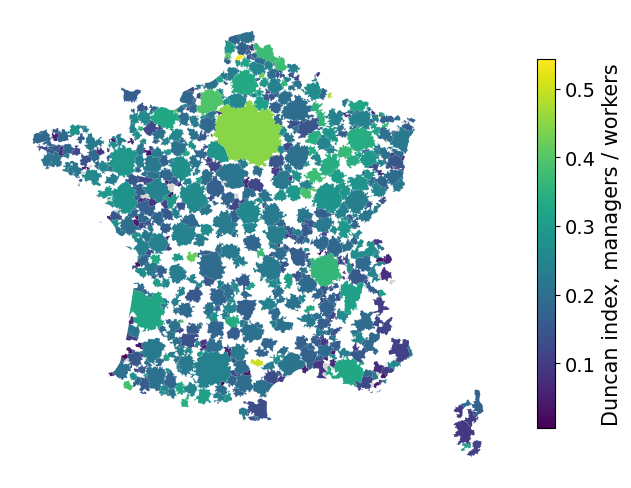

In [18]:
import geopandas as gpd

# The Insee map file is a zip that contains other zips: unpack everything once
MAP_DIR = INPUTS / "map_aav"
if not MAP_DIR.exists():
    with zipfile.ZipFile(next(INPUTS.glob("fonds_aav2020_2024*.zip"))) as z:
        z.extractall(MAP_DIR)
    for inner in MAP_DIR.glob("*.zip"):
        with zipfile.ZipFile(inner) as z:
            z.extractall(MAP_DIR / inner.stem)

# The layer of cities is the one whose name starts with "aav" (the other one is municipalities)
shp = [p for p in MAP_DIR.rglob("*.shp") if p.name.lower().startswith("aav")][0]
layer = gpd.read_file(shp)
print("Map layer:", shp.name, "|", len(layer), "rows | columns:", list(layer.columns))

# Find the column with the city code and give it the same name as in our table
code_col = [c for c in layer.columns if c.lower() in ("aav2020", "codgeo", "code", "aav")][0]
layer = layer.rename(columns={code_col: "AAV2020"})
layer["AAV2020"] = layer["AAV2020"].astype(str)

layer = layer.merge(cities[["AAV2020", "D_occupation"]], on="AAV2020", how="left")
layer = layer.to_crs(2154)                 # Lambert 93, the standard projection for France
c = layer.geometry.centroid
layer = layer[c.x.between(0, 1.3e6) & c.y.between(6.0e6, 7.2e6)]   # mainland France only

fig, ax = plt.subplots(figsize=(8, 8))
layer.plot(column="D_occupation", cmap="viridis", legend=True, ax=ax,
           missing_kwds={"color": "lightgrey"},
           legend_kwds={"label": "Duncan index, managers / workers", "shrink": 0.6})
ax.set_axis_off()
fig.savefig(FIG / "fig4_map.png")
plt.show()

In [19]:
print("Number of cities:", len(cities))
for title in DEFINITIONS.values():
    b1 = results[f"{title} (1)"].params["log_pop"]
    b2 = results[f"{title} (2)"].params["log_pop"]
    print(f"{title}: beta1 = {b1:.3f}, doubling population -> D + {0.69 * b1:.3f}; "
          f"with the control beta1 = {b2:.3f} ({100 * (b2 - b1) / b1:+.0f}%)")

Number of cities: 638
Managers / Workers: beta1 = 0.012, doubling population -> D + 0.008; with the control beta1 = -0.026 (-323%)
Graduates / No diploma: beta1 = 0.018, doubling population -> D + 0.013; with the control beta1 = -0.006 (-135%)
